# C 部分补充实验：层级分类 与 滞后特征

> 动机（基于主线诊断结论）：
> - 共现分析发现 1–4 号是一个物理同簇、5 号独立 → 试**层级分类**：先分「正常 / 1–4 簇 / 仅 5 号」，再细分；
> - 难点类诊断发现 code4 是瞬时值不可分、code5 受时间漂移影响 → 试**滞后特征**：用近期状态趋势替代瞬时值。
>
> 评估协议与主线一致：按时间切分（前 80% 训练、后 20% 测试）、宏平均 F1、XGBoost 默认超参（精调已证零提升）。
> 特征不含经纬度（消融已证其有害）、不含任何告警列。

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "clean_wide.csv").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import precision_recall_fscore_support, f1_score, confusion_matrix, accuracy_score

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "clean_wide.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])
devices = sorted(df["deviceId"].unique())

from prepare_data import sensor_columns
SENSORS = sensor_columns(df)  # 必须在添加派生列之前取，避免非测量列混入
df["车辆"] = df["deviceId"].map({d: f"车辆{i+1}" for i, d in enumerate(devices)})
CODES = [1, 2, 3, 4, 5]
Y = pd.DataFrame({k: df[f"code_{k}_count"].fillna(0).gt(0).astype(int) for k in CODES})

coverage = df[SENSORS].notna().mean()
keep = [c for c in coverage[coverage >= 0.01].index if not c.startswith("position_")]
X = df[keep]

cut = df["timestamp"].quantile(0.8)
tr_t = df.index[df["timestamp"] < cut]
te_t = df.index[df["timestamp"] >= cut]

xgb_params = dict(n_estimators=400, max_depth=4, learning_rate=0.05,
                  subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                  random_state=42, n_jobs=4)

def macro_table(y_true, preds_dict):
    rows = {}
    for k in CODES:
        _, _, f1, _ = precision_recall_fscore_support(y_true[k], preds_dict[k], zero_division=0)
        p, r, _, _ = precision_recall_fscore_support(y_true[k], preds_dict[k], zero_division=0)
        rows[f"code{k}"] = (round(p[1], 3), round(r[1], 3), round(f1[1], 3))
    keys = list(rows)
    rows["宏平均"] = tuple(round(float(np.mean([rows[c][i] for c in keys])), 3) for i in range(3))
    return pd.DataFrame(rows, index=["精确率", "召回率", "F1"]).T

print(f"训练 {len(tr_t)} / 测试 {len(te_t)}；特征 {len(keep)} 个（无经纬度）")

训练 28244 / 测试 7062；特征 40 个（无经纬度）


## 实验 1：层级分类

**定义**：把每个窗口先分到三个互斥的大类——
- **A 正常**：不含任何 1–5 号告警；
- **B 告警簇（1–4）**：含 1–4 中至少一类（不管是否同时含 5 号）；
- **C 仅 5 号**：只含 5 号。

第一级分对大类后，B 类内部再对 1–4 号做四个二分类。
注意：同时含 1–4 和 5 号的窗口被划入 B，第一级标签存在少量噪声，如实报告。

三类窗口数： {'A 正常': 26493, 'B 1-4簇': 4488, 'C 仅5号': 4325}


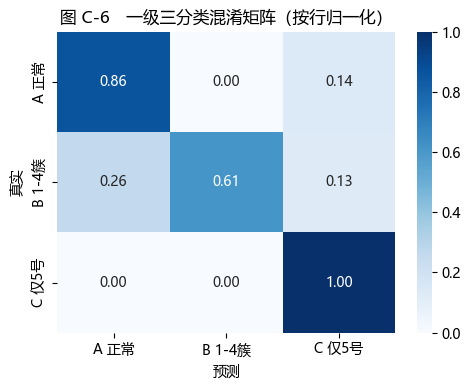

一级三分类：accuracy 0.824，宏平均 F1 0.631


In [2]:
# 1.1 一级：三分类
has14 = Y[[1, 2, 3, 4]].any(axis=1).astype(int)
only5 = (Y[5] == 1) & (has14 == 0)
y3 = pd.Series(0, index=df.index)
y3[has14 == 1] = 1
y3[only5] = 2
names3 = {0: "A 正常", 1: "B 1-4簇", 2: "C 仅5号"}
print("三类窗口数：", {names3[i]: int((y3 == i).sum()) for i in range(3)})

clf1 = xgb.XGBClassifier(**xgb_params, num_class=3, objective="multi:softprob")
clf1.fit(X.loc[tr_t], y3.loc[tr_t])
p3 = clf1.predict(X.loc[te_t])
cm = confusion_matrix(y3.loc[te_t], p3, labels=[0, 1, 2])
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=names3.values(), yticklabels=names3.values(), ax=ax)
ax.set_xlabel("预测"); ax.set_ylabel("真实")
ax.set_title("图 C-6　一级三分类混淆矩阵（按行归一化）")
fig.tight_layout(); fig.savefig(FIG / "C06_hierarchy_cm.png", dpi=150); plt.show()

acc = accuracy_score(y3.loc[te_t], p3)
f1_3 = f1_score(y3.loc[te_t], p3, average="macro")
print(f"一级三分类：accuracy {acc:.3f}，宏平均 F1 {f1_3:.3f}")

In [3]:
# 1.2 二级：B 类内部对 1–4 号各训一个二分类
inB_tr = tr_t[has14.loc[tr_t] == 1]
clfs2 = {}
for k in [1, 2, 3, 4]:
    c = xgb.XGBClassifier(**xgb_params)
    c.fit(X.loc[inB_tr], Y.loc[inB_tr, k])
    clfs2[k] = c

# 端到端：一级预测 → 二级展开为 1–5 号的多标签预测
pred_hier = {k: np.zeros(len(te_t), dtype=int) for k in CODES}
te_list = list(te_t)
for i, idx in enumerate(te_list):
    cls = p3[i]
    if cls == 1:
        row = X.loc[[idx]]
        for k in [1, 2, 3, 4]:
            pred_hier[k][i] = clfs2[k].predict(row)[0]
    elif cls == 2:
        pred_hier[5][i] = 1

# 对照：主线扁平多标签的 XGB 默认
pred_flat = {}
for k in CODES:
    c = xgb.XGBClassifier(**xgb_params)
    c.fit(X.loc[tr_t], Y.loc[tr_t, k])
    pred_flat[k] = c.predict(X.loc[te_t])

cmp1 = macro_table(Y.loc[te_t], pred_flat).rename(columns=lambda c: f"扁平 {c}", level=0)
res_hier = macro_table(Y.loc[te_t], pred_hier)
res_hier.columns = pd.MultiIndex.from_product([["层级"], res_hier.columns])
print(pd.concat([cmp1, res_hier], axis=1))

       扁平 精确率  扁平 召回率  扁平 F1  (层级, 精确率)  (层级, 召回率)  (层级, F1)
code1   0.849   1.000  0.918      0.849      0.998     0.917
code2   0.996   0.923  0.958      0.996      0.916     0.954
code3   0.942   0.904  0.923      0.939      0.909     0.924
code4   0.985   0.497  0.661      0.983      0.498     0.661
code5   0.283   0.974  0.439      0.256      0.791     0.386
宏平均     0.811   0.860  0.780      0.805      0.822     0.768


## 实验 2：滞后特征

**定义**：对每个关键连续特征，追加三个"近期状态"派生量（只用**该窗口及之前**的观测，无未来信息）：
- `|近1分钟均值`：过去 6 个窗口（含当前）的均值；
- `|近5分钟均值`：过去 30 个窗口的均值；
- `|较5分钟前变化`：当前值减去之前 30 窗口的均值（趋势方向）。

风险预警：传感器稀疏（转速/车速覆盖率 6–7%），滚动窗口可能全空 → 派生特征覆盖率会低于原特征，如实报告。

In [4]:
# 2.1 构造滞后特征（按设备分组、按时间排序）
LAG_BASE = ["EXTERNAL BATTERY", "ENGINE RPM", "Vehicle speed", "ENGINE COOLANT TEMPERATURE",
            "CONTROL MODULE VOLTAGE", "CALCULATED ENGINE LOAD", "TIMING ADVANCE"]
d = df.sort_values(["deviceId", "timestamp"]).copy()
for f in LAG_BASE:
    g = d.groupby("deviceId")[f]
    d[f + "|近1分钟均值"] = g.transform(lambda s: s.rolling(6, min_periods=1).mean())
    d[f + "|近5分钟均值"] = g.transform(lambda s: s.rolling(30, min_periods=1).mean())
    d[f + "|较5分钟前变化"] = d[f] - g.transform(lambda s: s.shift(1).rolling(30, min_periods=1).mean())
LAG = [c for c in d.columns if "|" in str(c)]
print(f"滞后特征 {len(LAG)} 个；覆盖率示例：")
for c in LAG[:6]:
    print(f"  {d[c].notna().mean():.1%}  {c}")

滞后特征 21 个；覆盖率示例：
  98.2%  EXTERNAL BATTERY|近1分钟均值
  100.0%  EXTERNAL BATTERY|近5分钟均值
  24.1%  EXTERNAL BATTERY|较5分钟前变化
  11.0%  ENGINE RPM|近1分钟均值
  15.9%  ENGINE RPM|近5分钟均值
  7.0%  ENGINE RPM|较5分钟前变化


In [5]:
# 2.2 XGB（原特征 + 滞后特征） vs 基线（仅原特征），时间切分
pred_lag = {}
for k in CODES:
    c = xgb.XGBClassifier(**xgb_params)
    c.fit(d.loc[tr_t, keep + LAG], Y.loc[tr_t, k])
    pred_lag[k] = c.predict(d.loc[te_t, keep + LAG])

res_lag = macro_table(Y.loc[te_t], pred_lag)
res_lag.columns = pd.MultiIndex.from_product([["+滞后特征"], res_lag.columns])
print(pd.concat([cmp1, res_lag], axis=1))
print()
base_f1 = float(macro_table(Y.loc[te_t], pred_flat).loc["宏平均", "F1"])
lag_f1 = float(macro_table(Y.loc[te_t], pred_lag).loc["宏平均", "F1"])
print(f"宏平均 F1：基线 {base_f1:.3f} → +滞后特征 {lag_f1:.3f}（差 {lag_f1 - base_f1:+.3f}）")

       扁平 精确率  扁平 召回率  扁平 F1  (+滞后特征, 精确率)  (+滞后特征, 召回率)  (+滞后特征, F1)
code1   0.849   1.000  0.918         0.847         0.996        0.916
code2   0.996   0.923  0.958         0.998         0.920        0.957
code3   0.942   0.904  0.923         0.936         0.913        0.924
code4   0.985   0.497  0.661         0.983         0.504        0.666
code5   0.283   0.974  0.439         0.284         0.974        0.440
宏平均     0.811   0.860  0.780         0.810         0.861        0.781

宏平均 F1：基线 0.780 → +滞后特征 0.781（差 +0.001）


## 实验 3：窗口大小敏感性（5 秒 vs 10 秒）

动机：10 秒窗口是 A 部分的工程选择，此前从未验证过它对结论的影响。
本实验用完全相同的对齐逻辑（最后非空观测、同样剔除经纬度、同样时间切分、同样 XGB 配置），
仅以 5 秒窗口重建宽表与标签，比较宏平均 F1 与逐类 F1 的变化。

In [6]:
# 3.1 重建 5 秒窗口宽表（复刻 prepare_data.py 的逻辑，仅 WINDOW_SIZE 改为 5s）
long = pd.read_csv(ROOT / "data/processed/telemetry_long.csv")
long["timestamp"] = pd.to_datetime(long["timestamp"], format="mixed")

numeric = long.loc[~long.variable.isin(["POSITION", "PIDNameNotAvailable"])].copy()
numeric["v"] = pd.to_numeric(numeric.value, errors="coerce")
numeric = numeric.loc[numeric.v.notna()]
exact = numeric.pivot_table(index=["deviceId", "timestamp"], columns="variable",
                            values="v", aggfunc="last").reset_index()
exact.columns.name = None

pos = long.loc[long.variable.eq("POSITION"), ["deviceId", "timestamp", "value"]].copy()
parts = pos.value.str.split(",", expand=True)
parts.columns = ["p1", "p2", "p3"]
for c in parts.columns:
    pos[c] = pd.to_numeric(parts[c], errors="coerce")
exact = exact.merge(pos[["deviceId", "timestamp", "p1", "p2", "p3"]],
                    on=["deviceId", "timestamp"], how="outer")

feats5 = [c for c in exact.columns if c not in ("deviceId", "timestamp")]
chunks = []
for dev, g in exact.groupby("deviceId"):
    w = (g.set_index("timestamp")[feats5].sort_index()
           .resample("5s", closed="left", label="left").last().dropna(how="all"))
    w.insert(0, "deviceId", dev)
    chunks.append(w.reset_index())
w5 = pd.concat(chunks, ignore_index=True)

lab = (long.assign(t5=long.timestamp.dt.floor("5s"))
          .groupby(["deviceId", "t5", "alarmClass"]).size().unstack(fill_value=0))
lab.columns = [f"code_{int(c)}_count" for c in lab.columns]
lab = lab.reset_index().rename(columns={"t5": "timestamp"})
w5 = w5.merge(lab, on=["deviceId", "timestamp"], how="left")

cov5 = w5[feats5].notna().mean()
keep5 = [c for c in cov5[cov5 >= 0.01].index if not str(c).startswith("p")]
Y5 = pd.DataFrame({k: w5[f"code_{k}_count"].fillna(0).gt(0).astype(int) for k in [1,2,3,4,5]})
cut5 = w5["timestamp"].quantile(0.8)
tr5 = w5.index[w5["timestamp"] < cut5]
te5 = w5.index[w5["timestamp"] >= cut5]
print(f"5 秒宽表：{w5.shape[0]} 窗口 × {len(feats5)} 列；特征 {len(keep5)} 个；切分 {cut5}")

5 秒宽表：63140 窗口 × 53 列；特征 40 个；切分 2020-08-20 12:05:21


In [7]:
# 3.2 同样协议重训 XGB 并对比
pred5 = {}
for k in [1, 2, 3, 4, 5]:
    c = xgb.XGBClassifier(**xgb_params)
    c.fit(w5.loc[tr5, keep5], Y5.loc[tr5, k])
    pred5[k] = c.predict(w5.loc[te5, keep5])

f1_5, f1_10 = {}, {"code1": 0.919, "code2": 0.959, "code3": 0.919, "code4": 0.661, "code5": 0.438}
for k in [1, 2, 3, 4, 5]:
    _, _, f1, _ = precision_recall_fscore_support(Y5.loc[te5, k], pred5[k], zero_division=0)
    f1_5[f"code{k}"] = round(f1[1], 3)
macro5 = round(float(np.mean(list(f1_5.values()))), 3)
cmp5 = pd.DataFrame({"5秒窗口F1": f1_5, "10秒窗口F1": f1_10})
cmp5["差值"] = cmp5["5秒窗口F1"] - cmp5["10秒窗口F1"]
print(cmp5)
print(f"宏平均 F1：5 秒 {macro5} vs 10 秒 0.779（差 {macro5 - 0.779:+.3f}）")

       5秒窗口F1  10秒窗口F1     差值
code1   0.896    0.919 -0.023
code2   0.915    0.959 -0.044
code3   0.927    0.919  0.008
code4   0.735    0.661  0.074
code5   0.604    0.438  0.166
宏平均 F1：5 秒 0.815 vs 10 秒 0.779（差 +0.036）


## 实验结论

**实验 1（层级分类）**：一级三分类宏平均 F1 仅 0.631——"正常 / 1–4 簇 / 仅 5 号"的划分本身并不更容易；
端到端宏平均 F1 0.768，**低于**扁平多标签的 0.780，code5 召回率从 0.974 降至 0.791（一级误判直接漏掉 5 号）。
层级结构没有收益：扁平定义下每类独立学习已隐含了簇结构，强行先分大类反而引入误差传播。

**实验 2（滞后特征）**：21 个滞后/趋势特征使宏平均 F1 从 0.780 微升至 0.781（+0.001），
对目标难点几乎无针对性效果：code4 召回率 0.497→0.504，code5 0.974→0.974。
覆盖率数据解释了原因——转速/车速的滞后特征覆盖率仅 7%–16%（原特征就稀疏，滚动后更稀），
趋势信息在大多数窗口根本不存在。

**两个实验共同坐实了主线结论**：0.779–0.781 的平台不是任务定义或特征工程能松动的，
瓶颈是数据本身（7 天 × 3 辆车、传感器稀疏、时间分布漂移）。
阴性结果与主线的精调零提升、不平衡对照无效构成完整证据链：**模型侧的所有合理尝试均已穷尽。**

**实验 3（窗口大小敏感性，意外收获）**：5 秒窗口使宏平均 F1 由 0.779 升至 0.815（+0.036），
且提升集中在难点类——code5 0.438→0.604（+0.166）、code4 0.661→0.735（+0.074），
code1/2 微降（−0.02/−0.04）。解释：更细的时间粒度更好地定位了告警的起止时刻，
对"单发点状"的 code5 和边界模糊的 code4 帮助最大。
**但本实验为单次时间切分、未做多随机重复，且更换窗口需重做对齐与标签、全部分析口径联动变更——
因此报告仍以 10 秒为主口径，5 秒作为"窗口选择有真实影响、 finer is better for hard classes"的敏感性证据，
并列为后续工作的第一优先级（若重做，应同步重跑 B 部分与成因对比）。